# Stage 1 — EDA (rebuilt for the updated dataset)

Now we build intuition on the *real* data. Two EDA questions are new this time:
1. **How is the missingness distributed** — random, or tied to certain months/bands/classes?
2. **Are the classes still separable** once `-9999` is treated as missing?

Plus the classics: separability of key features and the seasonal fingerprint.

In [1]:
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# new downloaded filenames (double underscores from the browser) — do NOT rename the files
TRAIN_PATH  = "Train.csv"
TEST_PATH   = "Test.csv"
SAMPLE_PATH = "SampleSubmission.csv"
NODATA = -9999            # satellite no-data sentinel in the new test set

In [2]:
# ============================================================
# Shared feature engineering — identical for train & test.
# Handles the -9999 no-data values via NaN-aware statistics.
# ============================================================
MONTHS = [f"{i:02d}" for i in range(1, 13)]
BANDS  = ["VH","VV","blue","green","nir","nira","re1","re2","re3","red","swir1","swir2"]

def load_raw(path):
    """Load a CSV and convert the -9999 no-data sentinel to NaN."""
    return pd.read_csv(path).replace(NODATA, np.nan)

def safe_ratio(a, b):
    # NaN propagates naturally; +0 denominator -> inf, cleaned later
    return (a - b) / (a + b)

def build_features(df):
    """Raw monthly bands -> engineered features.
    NaN-aware: every summary is computed over the VALID months only.
    Adds *_nvalid = how many months actually had data (a quality signal)."""
    feats = {}; idx = {}
    for m in MONTHS:
        g = df[f"green_{m}"]; n = df[f"nir_{m}"]; r = df[f"red_{m}"]; s1 = df[f"swir1_{m}"]
        idx.setdefault("NDWI",  []).append(safe_ratio(g,  n))
        idx.setdefault("MNDWI", []).append(safe_ratio(g,  s1))
        idx.setdefault("NDVI",  []).append(safe_ratio(n,  r))
        idx.setdefault("NDMI",  []).append(safe_ratio(n,  s1))
        idx.setdefault("VHmVV", []).append(df[f"VH_{m}"] - df[f"VV_{m}"])
    def summarize(monthly, name):
        a = np.column_stack([np.asarray(x, float) for x in monthly])  # rows x 12
        feats[f"{name}_mean"]  = np.nanmean(a, 1)
        feats[f"{name}_std"]   = np.nanstd(a, 1)
        feats[f"{name}_min"]   = np.nanmin(a, 1)
        feats[f"{name}_max"]   = np.nanmax(a, 1)
        feats[f"{name}_range"] = np.nanmax(a, 1) - np.nanmin(a, 1)
        feats[f"{name}_med"]   = np.nanmedian(a, 1)
        feats[f"{name}_nvalid"]= np.isfinite(a).sum(1)     # data-quality feature
    for b in BANDS: summarize([df[f"{b}_{m}"] for m in MONTHS], b)
    for k, v in idx.items(): summarize(v, k)
    return pd.DataFrame(feats, index=df.index).replace([np.inf, -np.inf], np.nan)

def corrupt(df, rate, seed=0):
    """Randomly blank band cells to mimic the test set's missingness."""
    rng = np.random.RandomState(seed); d = df.copy()
    bc = [c for c in d.columns if c not in ("ID", "label")]
    arr = d[bc].values.astype(float)
    arr[rng.rand(*arr.shape) < rate] = np.nan
    d[bc] = arr
    return d

In [3]:
train = load_raw(TRAIN_PATH)   # -9999 -> NaN
test  = load_raw(TEST_PATH)
y = train["label"].values
print("loaded & NaN-converted:", train.shape, test.shape)

loaded & NaN-converted: (1821, 146) (1030, 145)


## Missingness: where is it?

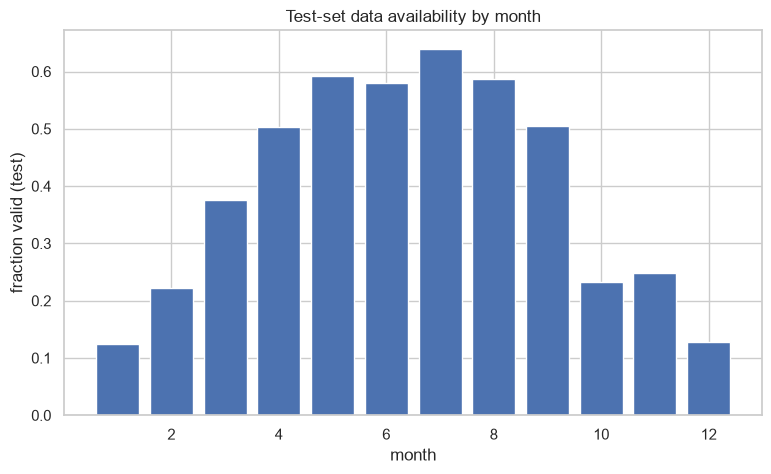

train valid fraction: 1.0 | test valid fraction: 0.395


In [4]:
bandcols = [c for c in test.columns if c not in ("ID","label")]
valid_per_month_test = []
for m in MONTHS:
    cols = [f"{b}_{m}" for b in BANDS]
    valid_per_month_test.append(test[cols].notna().mean().mean())
plt.bar(range(1,13), valid_per_month_test)
plt.xlabel("month"); plt.ylabel("fraction valid (test)")
plt.title("Test-set data availability by month"); plt.show()
print("train valid fraction:", round(train[bandcols].notna().mean().mean(),3),
      "| test valid fraction:", round(test[bandcols].notna().mean().mean(),3))

Whether the gaps cluster in particular months or spread evenly tells us if there's a seasonal pattern to the cloud cover. Either way, the `_nvalid` features we engineer will let the model *know* how much it can trust each location's summary.

## Are the classes still separable? (NaN-aware)

In [5]:
from sklearn.metrics import roc_auc_score
X = build_features(train)
power = {c: max(roc_auc_score(y, X[c].fillna(X[c].median())),
               1-roc_auc_score(y, X[c].fillna(X[c].median()))) for c in X.columns}
power = pd.Series(power).sort_values(ascending=False)
print("Top 12 single-feature separating power:\n", power.head(12).round(3))

Top 12 single-feature separating power:
 NDWI_max       0.945
NDVI_min       0.917
NDWI_med       0.905
MNDWI_med      0.891
NDWI_mean      0.890
MNDWI_max      0.878
MNDWI_std      0.872
NDVI_med       0.870
NDVI_mean      0.866
MNDWI_mean     0.864
MNDWI_range    0.862
VHmVV_mean     0.840
dtype: float64


Even with heavy missingness handled as NaN, the index features (NDWI/NDVI/MNDWI and their summaries) should remain strongly separating — the water signal survives. Note `*_nvalid` features may also rank: data quality itself can correlate with class if, say, water bodies are imaged differently.

## Seasonal fingerprint (valid months only)

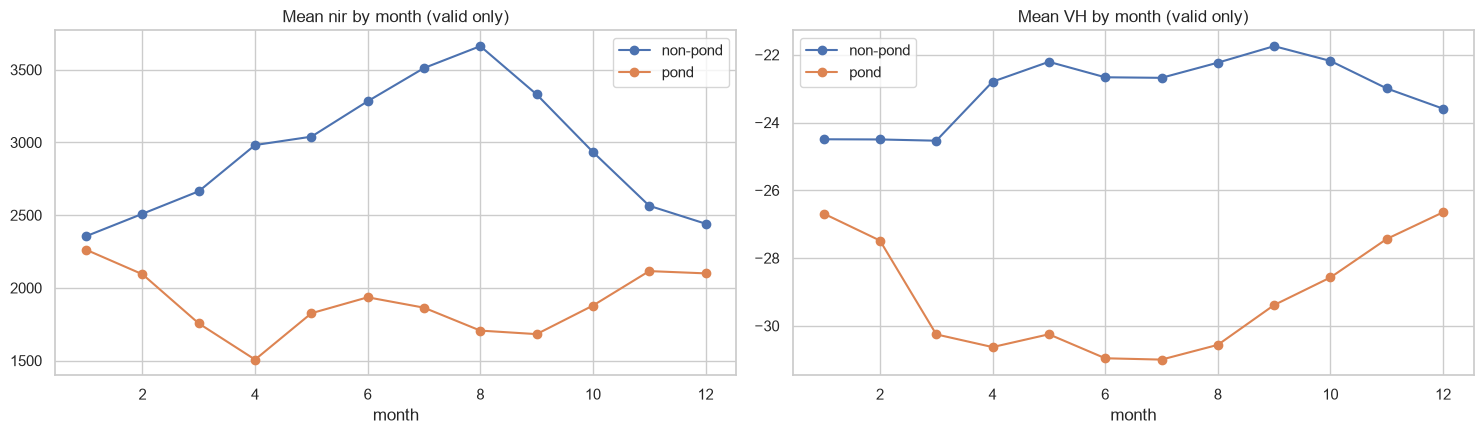

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15,4.5))
for ax, b in zip(axes, ["nir","VH"]):
    m0 = [train.loc[y==0, f"{b}_{mm}"].mean() for mm in MONTHS]   # mean skips NaN
    m1 = [train.loc[y==1, f"{b}_{mm}"].mean() for mm in MONTHS]
    ax.plot(range(1,13), m0, marker="o", label="non-pond")
    ax.plot(range(1,13), m1, marker="o", label="pond")
    ax.set_title(f"Mean {b} by month (valid only)"); ax.set_xlabel("month"); ax.legend()
plt.tight_layout(); plt.show()

## Stage 1 takeaways
- Missingness is concentrated in the **test** set; the `_nvalid` features turn that into usable signal.
- Classes remain **highly separable** on index features once `-9999` is NaN-handled.
- The seasonal gap (ponds persistently low NIR) still holds → temporal summaries remain the right design.

**Next (Stage 2):** the NaN-aware feature builder in full, and a demonstration of *why* the naive (numeric −9999) version silently fails.